In [1]:
'''Imports all required libraries 
for training the model'''
import os
from glob import glob
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import backend as K
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate,
    BatchNormalization, Dropout, Activation, Add, Multiply
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

2026-01-07 16:43:02.969086: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# REQUIREMENT: Do not add code from Tasks 2 or 4
# REQUIREMENT: All dataset prep (crop/pad/patch/directory structure) must be finalize before attempting this task.
patch_size = 192
patch_dir = "192_Data"

In [3]:
def f1(y_true, y_pred):
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = TP / (Positives+K.epsilon())
        return recall
    
    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = TP / (Pred_Positives+K.epsilon())
        return precision
    
    precision, recall = precision_m(y_true, y_pred), recall_m(y_true, y_pred)
    
    return 2*((precision*recall)/(precision+recall+K.epsilon()))

In [4]:
"""
Defines custom segmentation metrics and loss functions.
These help the U-Net learn thin/small roots and handle class imbalance.
"""

def tversky_index(y_true, y_pred, alpha=0.15, beta=0.85, smooth=1e-6):
    """
    Calculates the Tversky index (a Dice-like score).
    alpha controls penalty for false positives, beta controls penalty for false negatives.
    """
    y_true = K.flatten(tf.cast(y_true, tf.float32))
    y_pred = K.flatten(tf.cast(y_pred, tf.float32))
    y_pred = K.clip(y_pred, 1e-6, 1.0 - 1e-6)

    tp = K.sum(y_true * y_pred)
    fp = K.sum((1 - y_true) * y_pred)
    fn = K.sum(y_true * (1 - y_pred))

    return (tp + smooth) / (tp + alpha * fp + beta * fn + smooth)

def focal_tversky_loss(y_true, y_pred, alpha=0.15, beta=0.85, gamma=0.75):
    """
    Turns the Tversky index into a loss.
    gamma makes the loss focus more on hard pixels (misclassified areas).
    """
    ti = tversky_index(y_true, y_pred, alpha=alpha, beta=beta)
    return K.pow((1 - ti), gamma)

def weighted_bce(y_true, y_pred, pos_weight=3.0):
    """
    Computes weighted Binary Cross-Entropy (BCE).
    pos_weight > 1 gives more importance to root pixels to improve recall.
    """
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), 1e-6, 1.0 - 1e-6)

    bce = -(y_true * tf.math.log(y_pred) + (1.0 - y_true) * tf.math.log(1.0 - y_pred))
    w = 1.0 + (pos_weight - 1.0) * y_true
    return tf.reduce_mean(w * bce)

def bce_focal_tversky_loss(y_true, y_pred):
    """
    Combines weighted BCE and focal Tversky loss into one final loss.
    This balances clean background prediction with better root detection.
    """
    # Fixed weights for reproducibility
    bce_weight = 0.55   
    pos_weight = 3.0    

    bce = weighted_bce(y_true, y_pred, pos_weight=pos_weight)
    ft  = focal_tversky_loss(y_true, y_pred, alpha=0.15, beta=0.85, gamma=0.75)
    return bce_weight * bce + (1.0 - bce_weight) * ft


In [5]:

'''Defines a stronger U-Net model for thin root segmentation.
This version uses:
Residual blocks (helps gradients and feature learning)
Attention gates on skip connections (helps focus on root pixels)'''

def conv_bn_relu(x, filters, k=3):
    x = Conv2D(filters, (k, k), padding="same", kernel_initializer="he_normal")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    return x

def residual_block(x, filters, dropout=0.0):
    shortcut = x

    x = conv_bn_relu(x, filters, 3)
    if dropout and dropout > 0:
        x = Dropout(dropout)(x)

    x = Conv2D(filters, (3, 3), padding="same", kernel_initializer="he_normal")(x)
    x = BatchNormalization()(x)

    # Project shortcut if channels differ
    if K.int_shape(shortcut)[-1] != filters:
        shortcut = Conv2D(filters, (1, 1), padding="same", kernel_initializer="he_normal")(shortcut)
        shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])
    x = Activation("relu")(x)
    return x

def attention_gate(skip, gate, inter_channels):
    """
    Attention gate for skip connection.
    skip: encoder feature map
    gate: decoder feature map (after upsampling; same HxW as skip)
    """
    theta = Conv2D(inter_channels, (1, 1), padding="same")(skip)
    phi   = Conv2D(inter_channels, (1, 1), padding="same")(gate)

    x = Add()([theta, phi])
    x = Activation("relu")(x)

    psi = Conv2D(1, (1, 1), padding="same")(x)
    psi = Activation("sigmoid")(psi)

    return Multiply()([skip, psi])

def unet_thin_roots(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS, base_filters=16):
    inputs = Input((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))

    # -------------------
    # Encoder
    # (slightly lower dropout early helps preserve very thin structures)
    # -------------------
    c1 = residual_block(inputs, base_filters, dropout=0.00)
    p1 = MaxPooling2D((2, 2))(c1)

    c2 = residual_block(p1, base_filters * 2, dropout=0.05)
    p2 = MaxPooling2D((2, 2))(c2)

    c3 = residual_block(p2, base_filters * 4, dropout=0.10)
    p3 = MaxPooling2D((2, 2))(c3)

    c4 = residual_block(p3, base_filters * 8, dropout=0.15)
    p4 = MaxPooling2D((2, 2))(c4)

    # -------------------
    # Bottleneck
    # -------------------
    c5 = residual_block(p4, base_filters * 16, dropout=0.20)

    # -------------------
    # Decoder (Attention on skips)
    # -------------------
    u6 = Conv2DTranspose(base_filters * 8, (2, 2), strides=(2, 2), padding="same")(c5)
    a4 = attention_gate(c4, u6, inter_channels=base_filters * 4)
    u6 = concatenate([u6, a4])
    c6 = residual_block(u6, base_filters * 8, dropout=0.15)

    u7 = Conv2DTranspose(base_filters * 4, (2, 2), strides=(2, 2), padding="same")(c6)
    a3 = attention_gate(c3, u7, inter_channels=base_filters * 2)
    u7 = concatenate([u7, a3])
    c7 = residual_block(u7, base_filters * 4, dropout=0.10)

    u8 = Conv2DTranspose(base_filters * 2, (2, 2), strides=(2, 2), padding="same")(c7)
    a2 = attention_gate(c2, u8, inter_channels=base_filters)
    u8 = concatenate([u8, a2])
    c8 = residual_block(u8, base_filters * 2, dropout=0.05)

    u9 = Conv2DTranspose(base_filters, (2, 2), strides=(2, 2), padding="same")(c8)
    a1 = attention_gate(c1, u9, inter_channels=max(base_filters // 2, 1))
    u9 = concatenate([u9, a1])
    c9 = residual_block(u9, base_filters, dropout=0.00)

    outputs = Conv2D(1, (1, 1), activation="sigmoid")(c9)

    return Model(inputs=inputs, outputs=outputs)


In [6]:
"""
Creates the Residual + Attention U-Net model, compiles it with the chosen optimizer,
loss function, and F1 metric, and prints the model summary.
This is the configuration that will be used for training and validation.
"""

# Build the model (input is patch_size x patch_size with 1 grayscale channel)
model = unet_thin_roots(patch_size, patch_size, 1, base_filters=16)

# Compile the model with Adam optimizer, custom segmentation loss, and F1 metric
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=bce_focal_tversky_loss,   
    metrics=[f1]                   
)
# Print the model layers and parameter count
model.summary()


2026-01-07 16:43:09.225215: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1767804189.228144 4011970 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 45381 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:c1:00.0, compute capability: 8.6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 192, 192,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 192, 192,  │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 192, 192,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 192, 192,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 192, 192,  │      2,320 │ activation[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 192, 192,  │         32 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 192, 192,  │         64 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 192, 192,  │         64 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 192, 192,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 192, 192,  │          0 │ add[0][0]         │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 96, 96,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 96, 96,    │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 96, 96,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 96, 96,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 96, 96,    │          0 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 96, 96,    │      9,248 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 96, 96,    │        544 │ max_pooling2d[0]

 Total params: 2,059,565 (7.86 MB)

 Trainable params: 2,055,149 (7.84 MB)

 Non-trainable params: 4,416 (17.25 KB)

In [7]:
"""
Prepares the training data pipeline using patch files on disk.

What this cell does:
1) Collects and checks that training image patches and mask patches match 1:1.
2) Defines augmentation for each (image, mask) pair (same geometry for both).
3) Splits patches into 3 buckets (background / tiny-root / big-root) using mask pixel counts.
4) Builds a custom Keras Sequence that oversamples tiny-root patches to help learn thin roots.
5) Creates the final training generator used in model.fit().
"""
# Collect patch file paths (must match your folder structure: train_images/train and train_masks/train)
train_img_files  = sorted(glob(os.path.join(patch_dir, "train_images", "train", "*.png")))
train_mask_files = sorted(glob(os.path.join(patch_dir, "train_masks", "train", "*.png")))
print(f"Found {len(train_img_files)} images belonging to 1 class.")
print(f"Found {len(train_mask_files)} images belonging to 1 class.")

assert len(train_img_files) == len(train_mask_files), "Train img/mask count mismatch"

# Safety: ensure filenames match 1:1
for a, b in zip(train_img_files[:50], train_mask_files[:50]):
    if os.path.basename(a) != os.path.basename(b):
        raise ValueError(f"Train filename mismatch: {os.path.basename(a)} vs {os.path.basename(b)}")

def augment_pair(img_u8, msk_u8, rng):
    # img_u8: uint8 [0..255], msk_u8: uint8 [0..255]

    # ---- geometric (apply to both) ----
    if rng.random() < 0.5:
        img_u8 = cv2.flip(img_u8, 1)
        msk_u8 = cv2.flip(msk_u8, 1)

    if rng.random() < 0.5:
        angle = float(rng.uniform(-5.0, 5.0))
        h, w = img_u8.shape
        M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)

        img_u8 = cv2.warpAffine(
            img_u8, M, (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_REFLECT_101
        )
        msk_u8 = cv2.warpAffine(
            msk_u8, M, (w, h),
            flags=cv2.INTER_NEAREST,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

    # ---- photometric (image only) ----
    if rng.random() < 0.5:
        # CLAHE (helps match Kaggle contrast + boosts thin root visibility)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img_u8 = clahe.apply(img_u8)

    if rng.random() < 0.8:
        delta = int(rng.integers(-15, 16))
        img_u8 = np.clip(img_u8.astype(np.int16) + delta, 0, 255).astype(np.uint8)

    if rng.random() < 0.8:
        alpha = float(rng.uniform(0.85, 1.15))
        img_u8 = np.clip(alpha * img_u8.astype(np.float32), 0, 255).astype(np.uint8)

    if rng.random() < 0.5:
        gamma = float(rng.uniform(0.85, 1.25))
        img_u8 = np.clip(255.0 * (img_u8.astype(np.float32) / 255.0) ** gamma, 0, 255).astype(np.uint8)

    if rng.random() < 0.3:
        noise = rng.normal(0.0, 5.0, img_u8.shape).astype(np.float32)
        img_u8 = np.clip(img_u8.astype(np.float32) + noise, 0, 255).astype(np.uint8)

    return img_u8, msk_u8

def load_pair(img_path, mask_path, patch_size, augment=False, rng=None, dilate_mask=False):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    msk = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if img is None or msk is None:
        raise ValueError(f"Failed to read: {img_path} or {mask_path}")

    # Patches should already be patch_size x patch_size; enforce to catch dataset issues
    if img.shape != (patch_size, patch_size) or msk.shape != (patch_size, patch_size):
        raise ValueError(f"Bad patch shape: {os.path.basename(img_path)} img={img.shape} mask={msk.shape}")

    if augment:
        img, msk = augment_pair(img, msk, rng)

    # Convert mask to binary 0/1
    msk = (msk > 0).astype(np.uint8)

    # Optional: thicken thin roots slightly (minimal)
    if dilate_mask:
        kernel = np.ones((1, 1), np.uint8)   # minimal kernel
        msk = cv2.dilate(msk, kernel, iterations=1)

    img = img.astype(np.float32) / 255.0
    msk = msk.astype(np.float32)

    img = img[..., np.newaxis]
    msk = msk[..., np.newaxis]
    return img, msk

# Build indices (bg / tiny_pos / big_pos)
T = 10          # include very small/thin-root patches
TINY_MAX = 200  # pixels; "tiny roots" bucket upper bound for 192 patches

bg_idx = []
tiny_idx = []
big_idx = []

for i, mf in enumerate(train_mask_files):
    m = cv2.imread(mf, cv2.IMREAD_GRAYSCALE)
    if m is None:
        continue
    s = int((m > 0).sum())

    if s == 0:
        bg_idx.append(i)
    elif s < T:
        # treat ultra-tiny as background (likely annotation specks / negligible signal)
        bg_idx.append(i)
    elif s <= TINY_MAX:
        tiny_idx.append(i)
    else:
        big_idx.append(i)

bg_idx = np.array(bg_idx, dtype=np.int32)
tiny_idx = np.array(tiny_idx, dtype=np.int32)
big_idx = np.array(big_idx, dtype=np.int32)

all_idx = np.arange(len(train_img_files), dtype=np.int32)
if len(tiny_idx) == 0 or len(big_idx) == 0:
    raise ValueError("Bucket empty. Adjust T and/or TINY_MAX after inspecting mask pixel counts.")

class ThreeBucketTrainSequence(tf.keras.utils.Sequence):
    def __init__(
        self,
        img_files, mask_files,
        bg_idx, tiny_idx, big_idx,
        batch_size=16,
        p_tiny=0.50, p_big=0.30, p_bg=0.20,
        seed=1,
        patch_size=192,
    ):
        self.img_files = img_files
        self.mask_files = mask_files
        self.bg_idx = bg_idx
        self.tiny_idx = tiny_idx
        self.big_idx = big_idx

        self.batch_size = batch_size
        self.p_tiny = p_tiny
        self.p_big = p_big
        self.p_bg = p_bg

        self.rng = np.random.default_rng(seed)
        self.patch_size = patch_size

        # sanity: proportions
        if (p_tiny + p_big + p_bg) <= 0:
            raise ValueError("Sampling probabilities must sum to > 0.")

    def __len__(self):
        # No steps_per_epoch. This makes epochs potentially very long.
        return int(np.ceil(len(self.img_files) / self.batch_size))

    def __getitem__(self, _):
        n_tiny = int(round(self.batch_size * self.p_tiny))
        n_big  = int(round(self.batch_size * self.p_big))
        n_bg   = self.batch_size - n_tiny - n_big

        pick_tiny = self.rng.choice(self.tiny_idx, size=n_tiny, replace=True)
        pick_big  = self.rng.choice(self.big_idx,  size=n_big,  replace=True)
        pick_bg   = self.rng.choice(self.bg_idx,   size=n_bg,   replace=True)

        idxs = np.concatenate([pick_tiny, pick_big, pick_bg])
        self.rng.shuffle(idxs)

        X = np.zeros((self.batch_size, self.patch_size, self.patch_size, 1), dtype=np.float32)
        Y = np.zeros((self.batch_size, self.patch_size, self.patch_size, 1), dtype=np.float32)

        for k, i in enumerate(idxs):
            x, y = load_pair(
                self.img_files[i], self.mask_files[i],
                patch_size=self.patch_size,
                augment=True,
                rng=self.rng,
                dilate_mask=(self.rng.random() < 0.10)  # reduced probability
            )
            X[k] = x
            Y[k] = y

        return X, Y

train_img_gen = ThreeBucketTrainSequence(
    train_img_files, train_mask_files,
    bg_idx, tiny_idx, big_idx,
    batch_size=16,
    p_tiny=0.50, p_big=0.30, p_bg=0.20,
    seed=1,
    patch_size=patch_size,
)
train_mask_gen = None


Found 399475 images belonging to 1 class.
Found 399475 images belonging to 1 class.


In [8]:

"""
Creates the validation data pipeline.

What this cell does:
1) Sets up ImageDataGenerator to normalize validation images/masks to [0, 1].
2) Loads validation image patches and validation mask patches from disk.
3) Combines the two generators so the model receives (image_batch, mask_batch) pairs.
"""
datagen = ImageDataGenerator(rescale=1./255)

val_img_gen = datagen.flow_from_directory(
    os.path.join(patch_dir, "val_images"),
    target_size=(patch_size, patch_size),  
    class_mode=None,
    color_mode="grayscale",
    batch_size=16,
    seed=2, 
)

val_mask_gen = datagen.flow_from_directory(
    os.path.join(patch_dir, "val_masks"),
    target_size=(patch_size, patch_size), 
    class_mode=None,
    color_mode="grayscale",
    batch_size=16,
    seed=2, 
)
def combined_generator(img_gen, mask_gen):
    # Both generators must have the same number of batches
    num_batches = len(img_gen)
    while True:
        for i in range(num_batches):
            X = img_gen[i]
            Y = mask_gen[i]
            yield X, Y
val_generator = combined_generator(val_img_gen, val_mask_gen)

Found 14297 images belonging to 1 classes.
Found 14297 images belonging to 1 classes.


In [9]:
"""
Defines training callbacks to control overfitting and improve convergence.

- EarlyStopping: stops training when validation loss stops improving and restores the best weights.
- ReduceLROnPlateau: reduces the learning rate when validation loss plateaus to help the model improve further.
"""

# EarlyStopping()
cb = EarlyStopping(
    monitor='val_loss',
    patience=5,              
    restore_best_weights=True
)
# Add LR scheduling to improve generalization when val_loss plateaus
rlr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,            
    min_lr=1e-6,
    verbose=1
)

In [10]:
# This is where the magic happens
# REQUIREMENT: The epoch logs must be visible showing validation loss and validation f1.
history = model.fit(
    train_img_gen,                 
    validation_data=val_generator,
    validation_steps=len(val_img_gen),  
    epochs=50,
    callbacks=[cb, rlr]
)

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
2026-01-07 16:45:21.845348: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f6098003050 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-01-07 16:45:21.845386: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX A6000, Compute Capability 8.6
2026-01-07 16:45:22.227146: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-01-07 16:45:24.818917: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN 

    2/24968 ━━━━━━━━━━━━━━━━━━━━ 21:57 53ms/step - f1: 0.0251 - loss: 0.9735   

I0000 00:00:1767804347.680921 4012782 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


24968/24968 ━━━━━━━━━━━━━━━━━━━━ 873s 33ms/step - f1: 0.7052 - loss: 0.1636 - val_f1: 0.7180 - val_loss: 0.1137 - learning_rate: 1.0000e-04
Epoch 2/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 820s 33ms/step - f1: 0.7551 - loss: 0.1203 - val_f1: 0.7351 - val_loss: 0.1060 - learning_rate: 1.0000e-04
Epoch 3/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 824s 33ms/step - f1: 0.7656 - loss: 0.1142 - val_f1: 0.7529 - val_loss: 0.1011 - learning_rate: 1.0000e-04
Epoch 4/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 820s 33ms/step - f1: 0.7722 - loss: 0.1105 - val_f1: 0.7607 - val_loss: 0.1003 - learning_rate: 1.0000e-04
Epoch 5/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 860s 34ms/step - f1: 0.7766 - loss: 0.1079 - val_f1: 0.7562 - val_loss: 0.0997 - learning_rate: 1.0000e-04
Epoch 6/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 828s 33ms/step - f1: 0.7798 - loss: 0.1062 - val_f1: 0.7612 - val_loss: 0.0979 - learning_rate: 1.0000e-04
Epoch 7/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 823s 33ms/step - f1: 0.7821 - loss: 0.1049 - val_f1: 0.7553 -

In [11]:
# REQUIREMENT: Save your model, it is a deliverable
# REQUIREMENT: naming convention 'studentname_studentnumber_unet_model_patchsizepx.h5'
example_file_name = f'ahmed_245226_Residualunet_model_{patch_size}px.h5'
print(example_file_name)
model.save(example_file_name)

ahmed_245226_Residualunet_model_192px.h5


In [12]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
best_val_loss = min(history.history['val_loss'])
best_val_f1 = max(history.history['val_f1'])
print(f"Best validation loss: {best_val_loss}")
print(f"Best validation f1: {best_val_f1}")

Best validation loss: 0.09372244775295258
Best validation f1: 0.7870237827301025


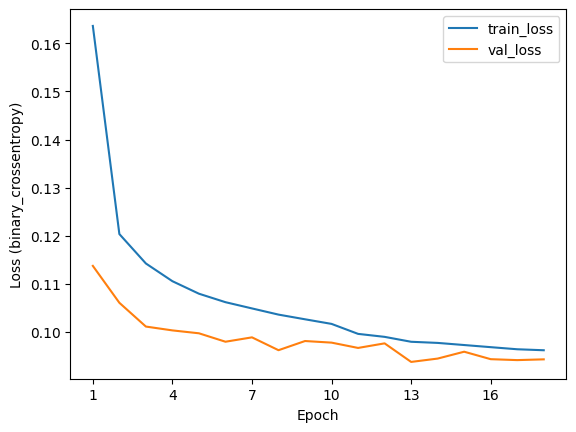

In [13]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = np.arange(1, len(loss) + 1)

plt.plot(epochs, loss, label='train_loss')
plt.plot(epochs, val_loss, label='val_loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss (binary_crossentropy)')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))

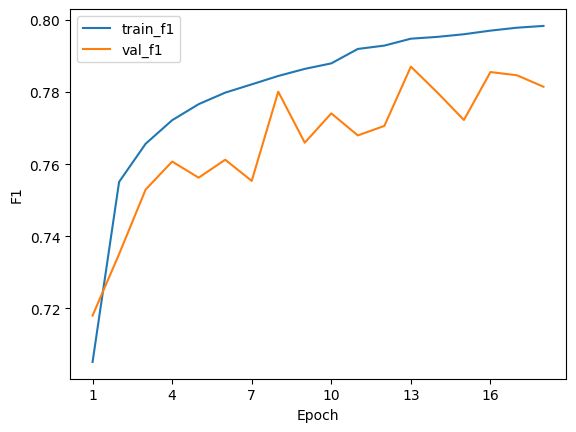

In [14]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
train_f1 = history.history['f1']
val_f1 = history.history['val_f1']

epochs = np.arange(1, len(train_f1) + 1)

plt.plot(epochs, train_f1, label='train_f1')
plt.plot(epochs, val_f1, label='val_f1')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('F1')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))